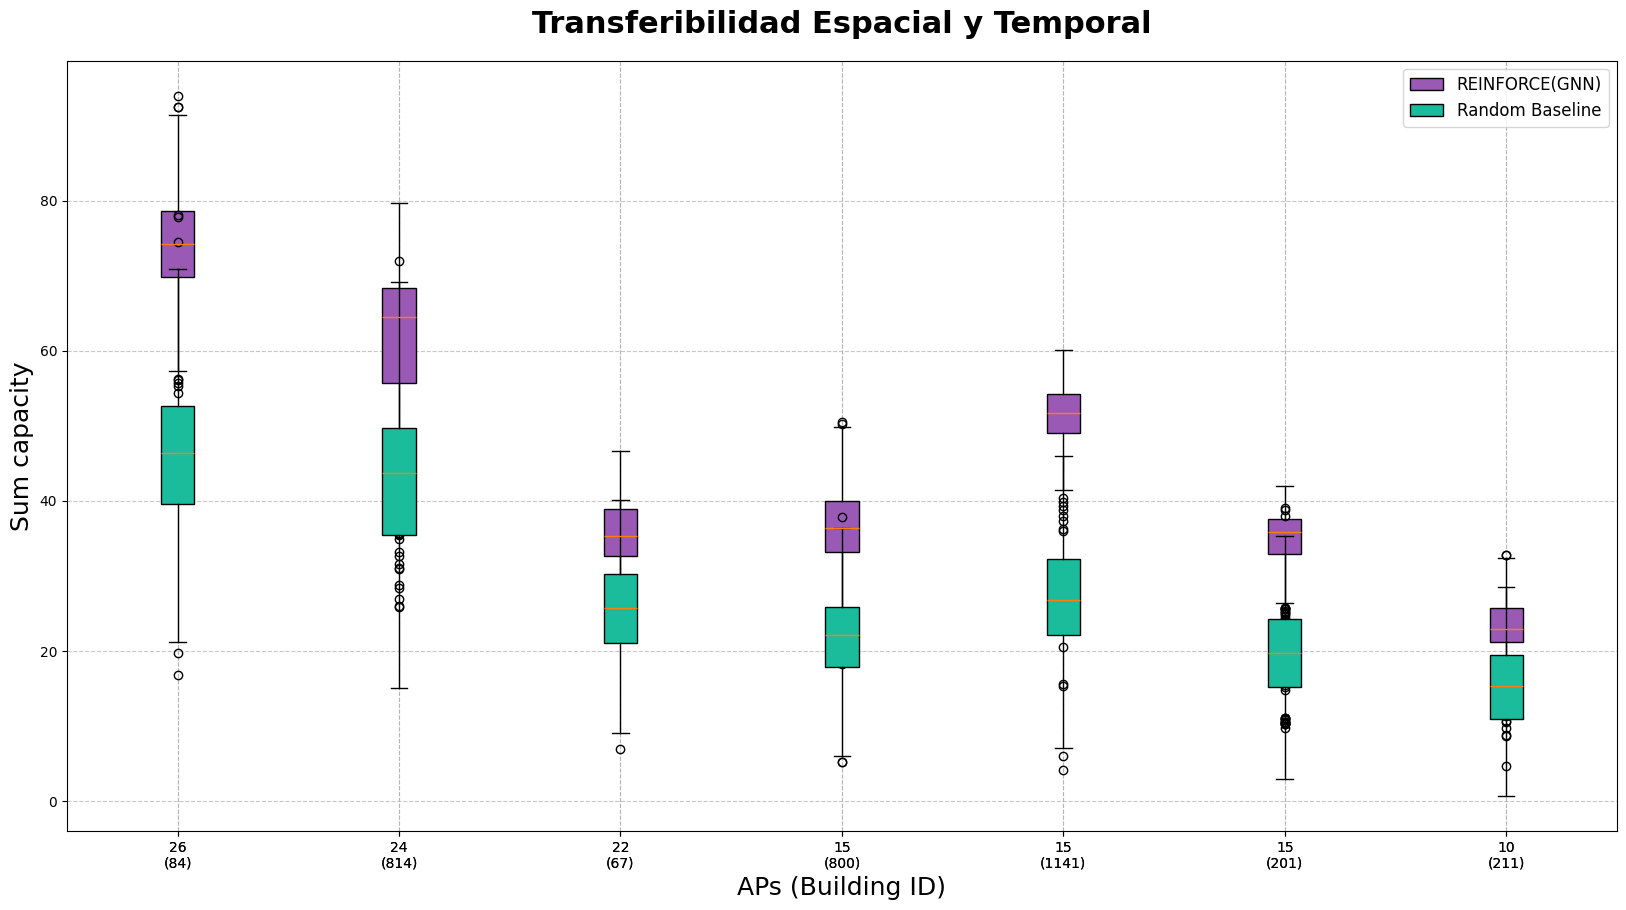

In [8]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch

# Configuración basada en la referencia
considered_graphs = [84, 814,67, 800, 1141, 201, 211]
nodes = ['26', '24', '22', '15', '15', '15', '10', '10']
colors = ['#9B59B6', '#1ABC9C'] # darkblue para GNN, darkgray para Random

base_path = '/Users/nahuelpineyro/NetROML_2.0/'
gen_path = os.path.join(base_path, 'Version1/results/temporal_test/')

all_plot_values = []

for graph in considered_graphs:
    plot_values = []
    
    # 1. Cargar GNN (Generalization)
    val_pkl = os.path.join(gen_path, f'test_results_b{graph}.pkl')
    if os.path.exists(val_pkl):
        with open(val_pkl, 'rb') as file:
            val_data = pickle.load(file)
            # Aplanar y convertir
            flat_gnn = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else d for d in val_data]).flatten()
            plot_values.append(flat_gnn[:1000]) # Usando top 1000 como en la referencia
    
    # 2. Cargar Baseline Random para CADA edificio
    baseline_path = os.path.join(base_path, f'Version1/results/2_4_{graph}/torch_resultss/baseline_random_1.pkl')
    if os.path.exists(baseline_path):
        with open(baseline_path, 'rb') as file:
            rand_data = pickle.load(file)
            # Extraer y aplanar los datos
            flat_rand = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else np.array(d).flatten() for d in rand_data]).flatten()
            plot_values.append(flat_rand[:1000])
            
    all_plot_values.append(plot_values)

    from matplotlib.patches import Patch

# Generar el Boxplot exactamente como en la referencia
fig, ax = plt.subplots(figsize=(20, 10))
ax.set_title('Transferibilidad Espacial y Temporal', fontsize=22, fontweight='bold', pad=20)
ax.set_ylabel('Sum capacity', fontsize=18)
ax.set_xlabel('APs (Building ID)', fontsize=18)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

i = 0
for graph in considered_graphs:
    data_to_plot = all_plot_values[i]
    if not data_to_plot:
        i += 1
        continue
        
    # Creamos etiquetas: "APs (Building ID)"
    label_text = f"{nodes[i]}\n({graph})"
    current_labels = [label_text] * len(data_to_plot)
    
    # Posiciones iguales para que compartan la base
    current_positions = [i] * len(data_to_plot)
    
    # Usamos tick_labels para evitar DeprecationWarning en versiones nuevas de matplotlib
    bplot = ax.boxplot(data_to_plot, 
                       positions=current_positions,
                       patch_artist=True, 
                       tick_labels=current_labels)
    
    # Aplicar colores
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
    
    i = i + 1

ax.grid(True, linestyle='--', alpha=0.7)

# Añadir leyenda manual para identificar los colores
legend_elements = [
    Patch(facecolor='#9B59B6', edgecolor='black', label='REINFORCE(GNN)'),
    Patch(facecolor='#1ABC9C', edgecolor='black', label='Random Baseline')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=12)

# Guardar imagen en la carpeta de resultados de generalización
plt.show()



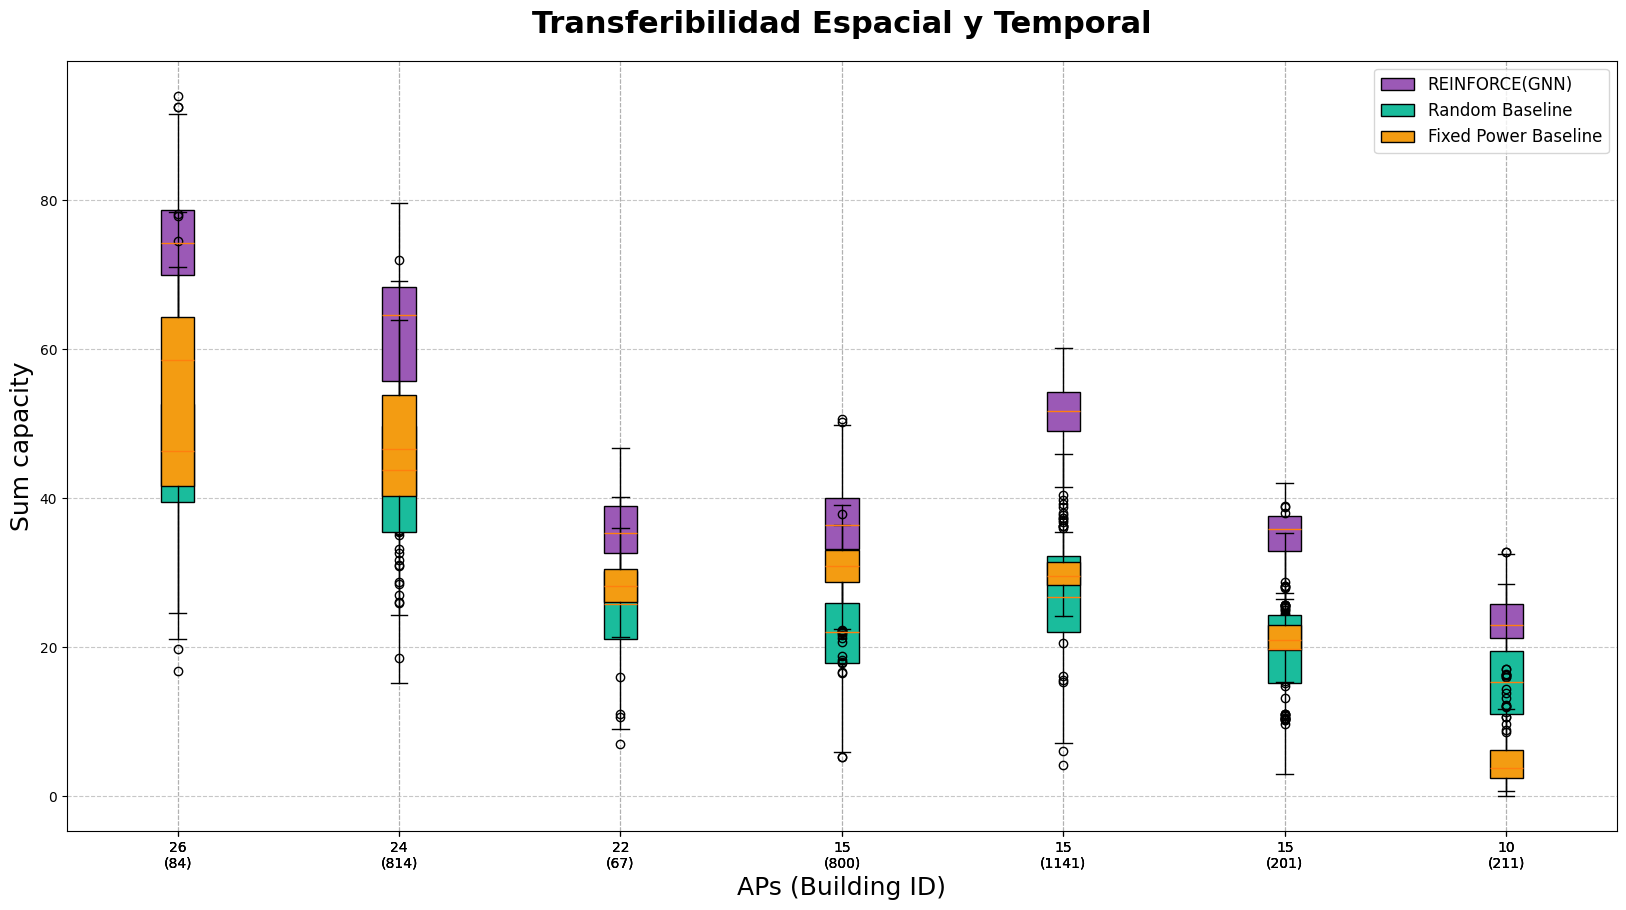

In [9]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Patch

# Configuración basada en la referencia
considered_graphs = [84, 814, 67, 800, 1141, 201, 211]
nodes = ['26', '24', '22', '15', '15', '15', '10', '10']
# Se añade un tercer color (ej. un tono anaranjado/dorado) para el nuevo baseline
colors = ['#9B59B6', '#1ABC9C', '#F39C12'] 

base_path = '/Users/nahuelpineyro/NetROML_2.0/'
gen_path = os.path.join(base_path, 'Version1/results/temporal_test/')

all_plot_values = []

for graph in considered_graphs:
    plot_values = []
    
    # 1. Cargar GNN (Generalization)
    val_pkl = os.path.join(gen_path, f'test_results_b{graph}.pkl')
    if os.path.exists(val_pkl):
        with open(val_pkl, 'rb') as file:
            val_data = pickle.load(file)
            # Aplanar y convertir
            flat_gnn = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else d for d in val_data]).flatten()
            plot_values.append(flat_gnn[:1000]) # Usando top 1000 como en la referencia
    
    # 2. Cargar Baseline Random para CADA edificio
    # Nota: Asegúrate de si la carpeta es 'torch_results' o 'torch_resultss'
    baseline_path = os.path.join(base_path, f'Version1/results/2_4_{graph}/torch_resultss/baseline_random_1.pkl')
    if os.path.exists(baseline_path):
        with open(baseline_path, 'rb') as file:
            rand_data = pickle.load(file)
            # Extraer y aplanar los datos
            flat_rand = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else np.array(d).flatten() for d in rand_data]).flatten()
            plot_values.append(flat_rand[:1000])
            
    # 3. Cargar Baseline Fixed Power (Pmax/m en canal fijo) para CADA edificio
    # Usando el nombre con el que se guarda ahora en tu script baseline_train.py
    baseline3_path = os.path.join(base_path, f'Version1/results/2_4_{graph}/torch_results/baseline_fixed_power_trajectory.pkl')
    if os.path.exists(baseline3_path):
        with open(baseline3_path, 'rb') as file:
            fixed_data = pickle.load(file)
            flat_fixed = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else np.array(d).flatten() for d in fixed_data]).flatten()
            plot_values.append(flat_fixed[:1000])
            
    all_plot_values.append(plot_values)

# Generar el Boxplot exactamente como en la referencia
fig, ax = plt.subplots(figsize=(20, 10))
ax.set_title('Transferibilidad Espacial y Temporal', fontsize=22, fontweight='bold', pad=20)
ax.set_ylabel('Sum capacity', fontsize=18)
ax.set_xlabel('APs (Building ID)', fontsize=18)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

i = 0
for graph in considered_graphs:
    data_to_plot = all_plot_values[i]
    if not data_to_plot:
        i += 1
        continue
        
    # Creamos etiquetas: "APs (Building ID)"
    label_text = f"{nodes[i]}\n({graph})"
    current_labels = [label_text] * len(data_to_plot)
    
    # Posiciones iguales para que compartan la base
    current_positions = [i] * len(data_to_plot)
    
    # Usamos tick_labels para evitar DeprecationWarning en versiones nuevas de matplotlib
    bplot = ax.boxplot(data_to_plot, 
                       positions=current_positions,
                       patch_artist=True, 
                       tick_labels=current_labels)
    
    # Aplicar colores: zip automáticamente mapea hasta la cantidad de boxes dibujadas
    for patch, color in zip(bplot['boxes'], colors[:len(data_to_plot)]):
        patch.set_facecolor(color)
    
    i = i + 1

ax.grid(True, linestyle='--', alpha=0.7)

# Añadir leyenda manual para identificar los colores
legend_elements = [
    Patch(facecolor='#9B59B6', edgecolor='black', label='REINFORCE(GNN)'),
    Patch(facecolor='#1ABC9C', edgecolor='black', label='Random Baseline'),
    Patch(facecolor='#F39C12', edgecolor='black', label='Fixed Power Baseline')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=12)

# Guardar imagen en la carpeta de resultados de generalización
image_path = os.path.join(gen_path, 'generalization_boxplot_reference_style.png')
plt.savefig(image_path, dpi=300, bbox_inches='tight')
plt.show()


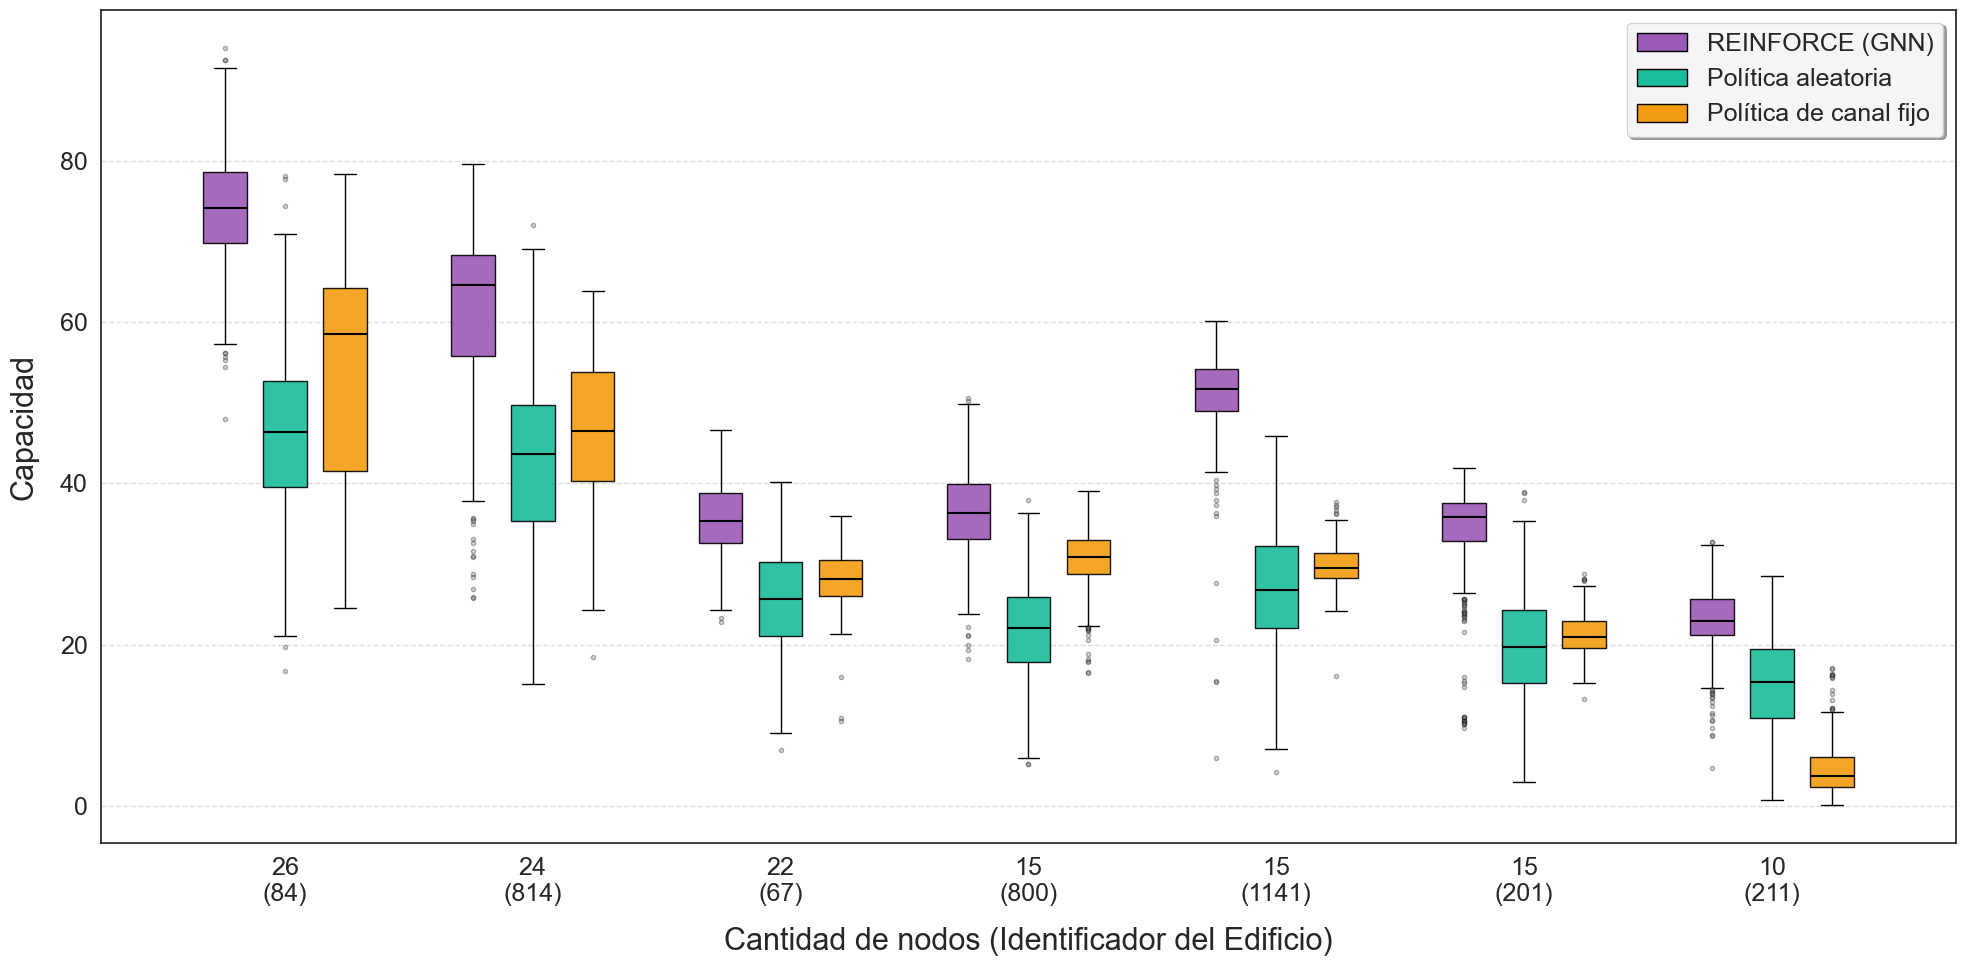

In [1]:
import os
import pickle
import numpy as np
import seaborn as sns  # <-- Importamos seaborn para mejorar la estética base
import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Patch

# Configuración basada en la referencia
considered_graphs = [84, 814, 67, 800, 1141, 201, 211]
nodes = ['26', '24', '22', '15', '15', '15', '10', '10']
# Se añade un tercer color (naranja/dorado) para el nuevo baseline
colors = ['#9B59B6', '#1ABC9C', '#F39C12'] 

base_path = '/Users/nahuelpineyro/NetROML_2.0/'
gen_path = os.path.join(base_path, 'Version1/results/temporal_test/')

all_plot_values = []

for graph in considered_graphs:
    plot_values = []
    
    # 1. Cargar GNN (Generalization)
    val_pkl = os.path.join(gen_path, f'test_results_b{graph}.pkl')
    if os.path.exists(val_pkl):
        with open(val_pkl, 'rb') as file:
            val_data = pickle.load(file)
            flat_gnn = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else d for d in val_data]).flatten()
            plot_values.append(flat_gnn[:1000])
    
    # 2. Cargar Baseline Random
    baseline_path = os.path.join(base_path, f'Version1/results/2_4_{graph}/torch_resultss/baseline_random_1.pkl')
    if os.path.exists(baseline_path):
        with open(baseline_path, 'rb') as file:
            rand_data = pickle.load(file)
            flat_rand = np.concatenate([d.detach().cpu().numpy() if hasattr(d, 'detach') else np.array(d).flatten() for d in rand_data]).flatten()
            plot_values.append(flat_rand[:1000])
            
    # 3. Cargar Baseline Fixed Power
    baseline3_path = os.path.join(base_path, f'Version1/results/2_4_{graph}/torch_results/baseline_fixed_power_trajectory.pkl')
    if os.path.exists(baseline3_path):
        with open(baseline3_path, 'rb') as file:
            fixed_data = pickle.load(file)
            flat_fixed = np.array(fixed_data).flatten()
            plot_values.append(flat_fixed[:1000])
            
    all_plot_values.append(plot_values)

# ==========================================
# GENERACIÓN DEL GRÁFICO (VERSIÓN PRO - AGRUPADA)
# ==========================================

# NUEVO: Aplicamos un tema limpio y escalamos la base de todas las letras un 50%
sns.set_theme(style="white", font_scale=1.5)

fig, ax = plt.subplots(figsize=(20, 10))

# NUEVO: Aumentamos el tamaño de título y ejes de forma agresiva para que destaquen
# ax.set_title('Transferibilidad Espacial y Temporal', fontsize=28, fontweight='bold', pad=20)
ax.set_ylabel('Capacidad', fontsize=22, labelpad=15)
ax.set_xlabel('Cantidad de nodos (Identificador del Edificio)', fontsize=22, labelpad=15)

# NUEVO: Agrandamos los números de la cuadrícula y las etiquetas X usando el objeto ax directamente
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=18)

# Listas para guardar las posiciones de las etiquetas del eje X
center_positions = []
center_labels = []

# Ancho base para las cajas y separación
box_width = 0.22

for i, graph in enumerate(considered_graphs):
    data_to_plot = all_plot_values[i]
    if not data_to_plot:
        continue
        
    num_boxes = len(data_to_plot)
    
    # LÓGICA DE AGRUPACIÓN (OFFSETS)
    if num_boxes == 1:
        offsets = [0]
    elif num_boxes == 2:
        offsets = [-box_width/1.8, box_width/1.8]
    else:
        # Para 3 cajas: una a la izquierda, una en el centro (0), una a la derecha
        offsets = [-box_width*1.1, 0, box_width*1.1]
        
    current_positions = [i + off for off in offsets]
    
    # Dibujar las cajas desplazadas
    bplot = ax.boxplot(data_to_plot, 
                       positions=current_positions,
                       widths=box_width*0.8,
                       patch_artist=True,
                       medianprops=dict(color="black", linewidth=1.5),
                       flierprops=dict(marker='o', markerfacecolor='gray', markersize=3, alpha=0.3))
    
    # Aplicar colores limpios
    for patch, color in zip(bplot['boxes'], colors[:num_boxes]):
        patch.set_facecolor(color)
        patch.set_edgecolor('black')
        patch.set_alpha(0.9)
        
    # Guardar el centro exacto para poner el label "APs (Building ID)" UNA SOLA VEZ por grupo
    center_positions.append(i)
    center_labels.append(f"{nodes[i]}\n({graph})")

# Setear los labels limpios en la base
ax.set_xticks(center_positions)
ax.set_xticklabels(center_labels)

# Mejorar la grilla para que se vea más limpio (solo líneas horizontales)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True) # Para que la grilla quede por detrás de las cajas y no las raye

# Añadir leyenda manual profesional
legend_elements = [
    Patch(facecolor='#9B59B6', edgecolor='black', label='REINFORCE (GNN)'),
    Patch(facecolor='#1ABC9C', edgecolor='black', label='Política aleatoria'),
    Patch(facecolor='#F39C12', edgecolor='black', label='Política de canal fijo')
]
# NUEVO: Aumentamos el fontsize de la leyenda a 18
ax.legend(handles=legend_elements, loc='upper right', fontsize=18, framealpha=0.9, shadow=True)

# Ajuste automático de márgenes para que nada quede fuera del lienzo al guardarlo
plt.tight_layout()

# Guardar imagen
image_path = os.path.join(gen_path, '../../../boxplot_v1.pdf')
plt.savefig(image_path, dpi=300, bbox_inches='tight')
plt.show()
